In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
TASK = Path.cwd().parent.parent
ROOT = TASK.parent
INPUT, OUTPUT = TASK/'input', TASK/'output/exploratory'
OUTPUT.mkdir(parents=True,exist_ok=True)
CONFIG = json.loads((ROOT / 'config.json').read_text())
EPS, Y, SEED = CONFIG['eps'], CONFIG['last_year'], CONFIG['seed']

In [3]:
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
ORDER = ['empirical_complete'] + CONFIG['models']
PALETTE = dict(zip(ORDER,sns.color_palette('colorblind',len(ORDER))))
PALETTE['se_hurdle_s'] = '#333333'
DASHES = dict(zip(ORDER, ['', (4,2), (1,1), (6,2,1,2), (3,1,1,1), (8,2),(2,1,2,3)]))
MARKERS = dict(zip(ORDER,['o','s','^','D','v','P','X']))
SECONDARY = OUTPUT/'secondary'
SECONDARY.mkdir(exist_ok=True)
VIEWS = [(OUTPUT,CONFIG['primary_plot_models']), (SECONDARY,CONFIG['models'])]
def save(fig,name):
    fig.tight_layout()
    fig.savefig(DEST / (name+'.png'),dpi=180,bbox_inches='tight')
    fig.savefig(DEST / (name+'.pdf'),bbox_inches='tight')
    plt.show()
    plt.close(fig)
def lines(data,x,y,ax):
    sns.lineplot(data=data,x=x,y=y,hue='source',style='source',hue_order=ORDER,style_order=ORDER,
                 palette=PALETTE,dashes=DASHES,markers=MARKERS,markersize=3,ax=ax)

In [4]:
moments = pd.read_csv(INPUT / 'annual_moments.csv')
ranks = pd.read_csv(INPUT / 'rank_correlations.csv')
qq = pd.read_csv(INPUT / 'window_qq_points.csv')
hazard = pd.read_csv(INPUT / 'restart_hazard.csv')
maximum = pd.read_csv(INPUT / 'year_of_maximum.csv')
params = pd.read_csv(INPUT / 'simulation/fit/ar6_6/parameters.csv')

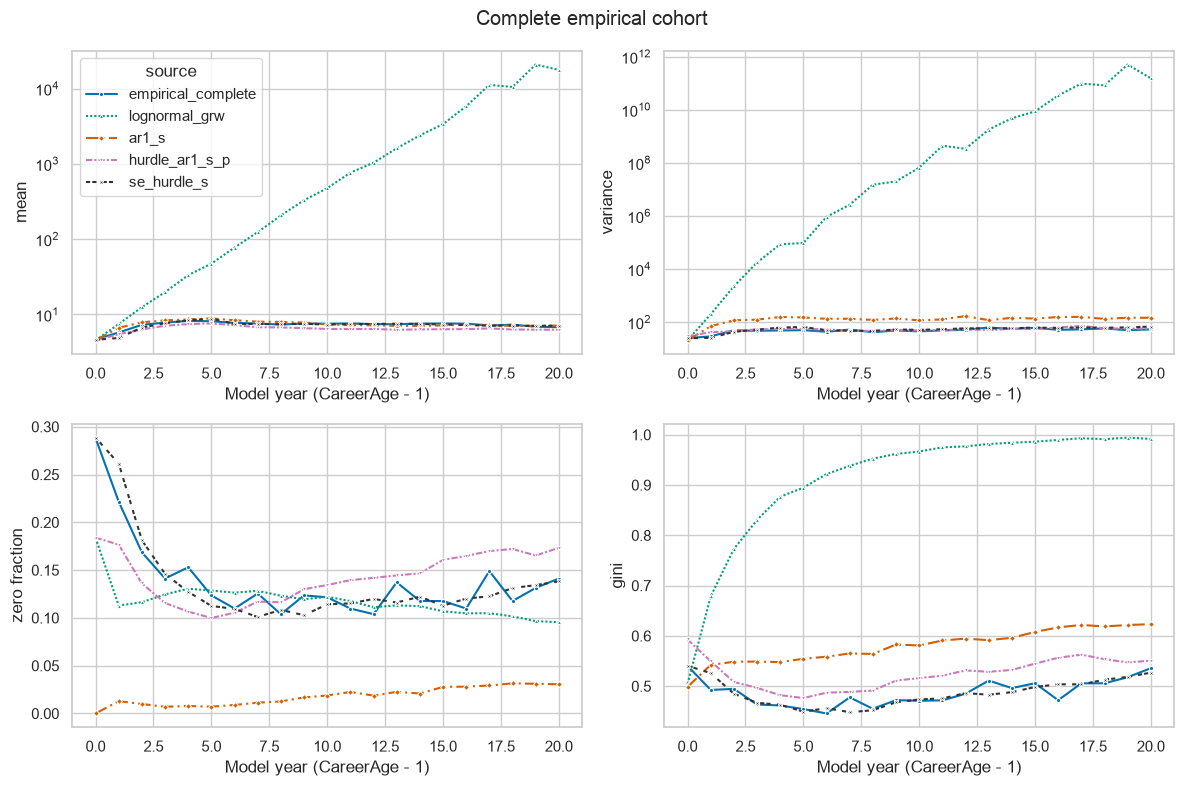

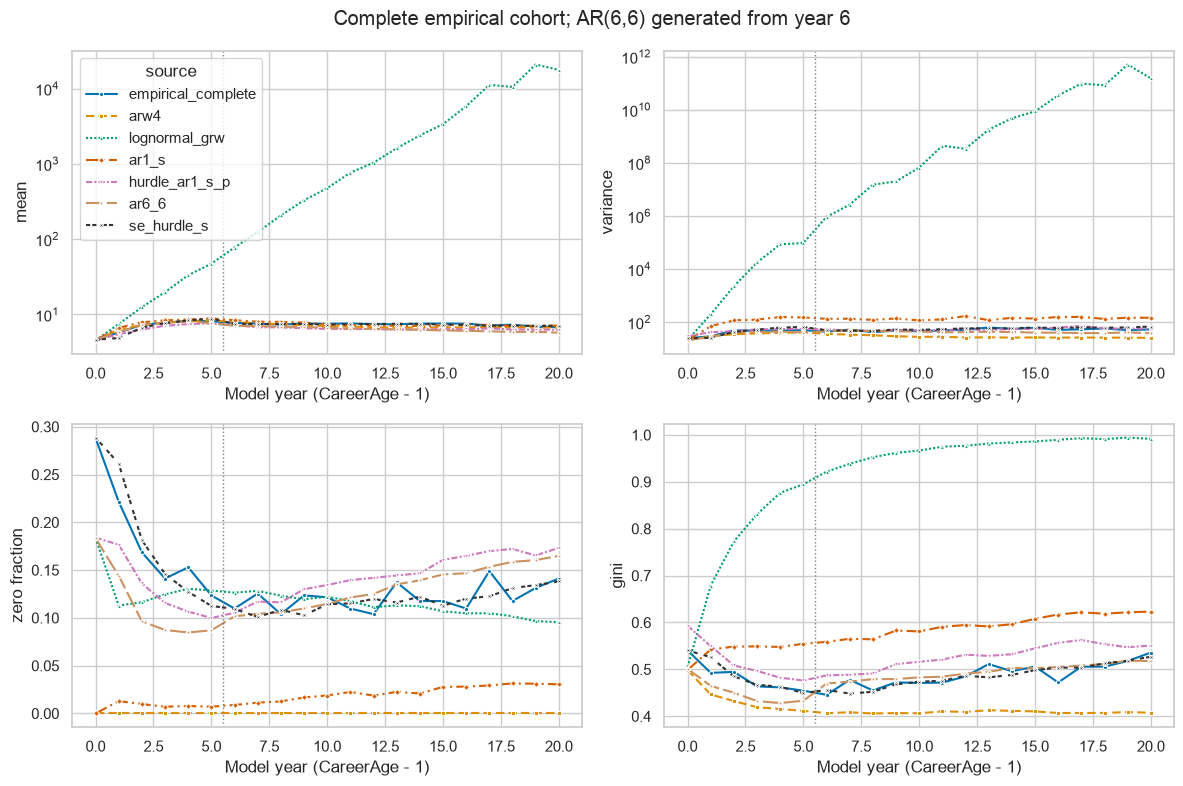

In [5]:
for DEST, selected in VIEWS:
    ORDER = ['empirical_complete'] + selected
    fig,axes = plt.subplots(2,2,figsize=(12,8))
    subset = moments.loc[moments.source.isin(ORDER)]
    for ax,metric in zip(axes.flat,['mean','variance','zero_fraction','gini']):
        lines(subset,'age',metric,ax)
        ax.set(xlabel='Model year (CareerAge - 1)',ylabel=metric.replace('_',' '))
        if 'ar6_6' in selected: ax.axvline(5.5,color='.5',linestyle=':',linewidth=1)
        if metric in ['mean','variance']: ax.set_yscale('log')
        if ax!=axes.flat[0]: ax.legend().remove()
    fig.suptitle('Complete empirical cohort' + ('; AR(6,6) generated from year 6' if 'ar6_6' in selected else ''))
    save(fig,'annual_moments')

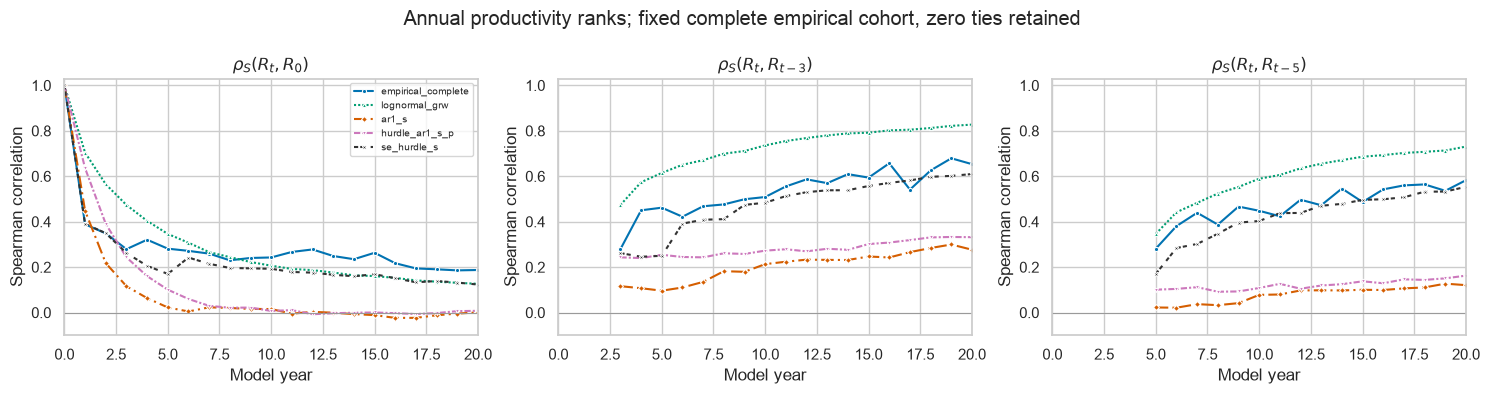

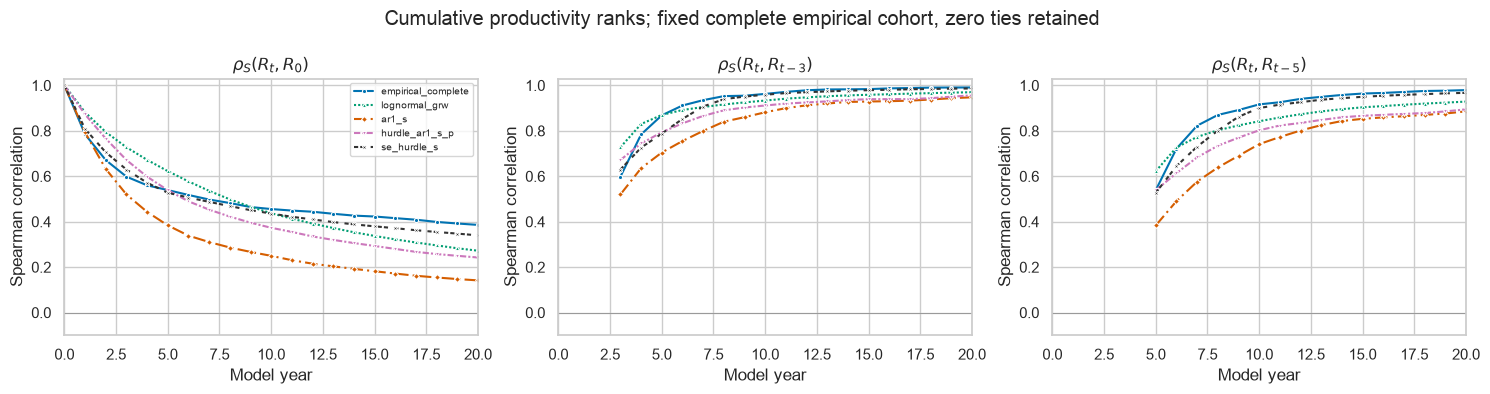

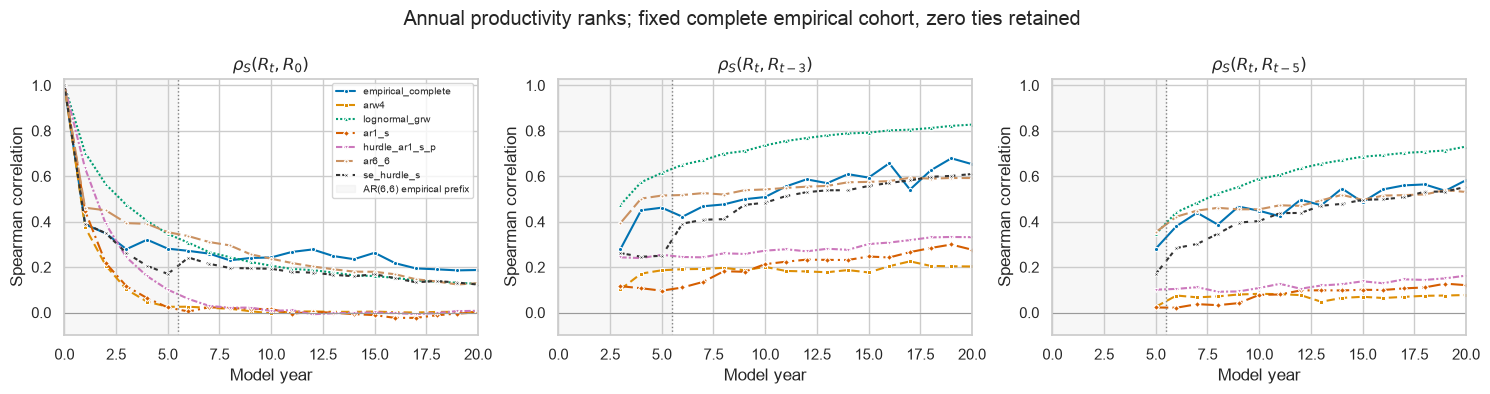

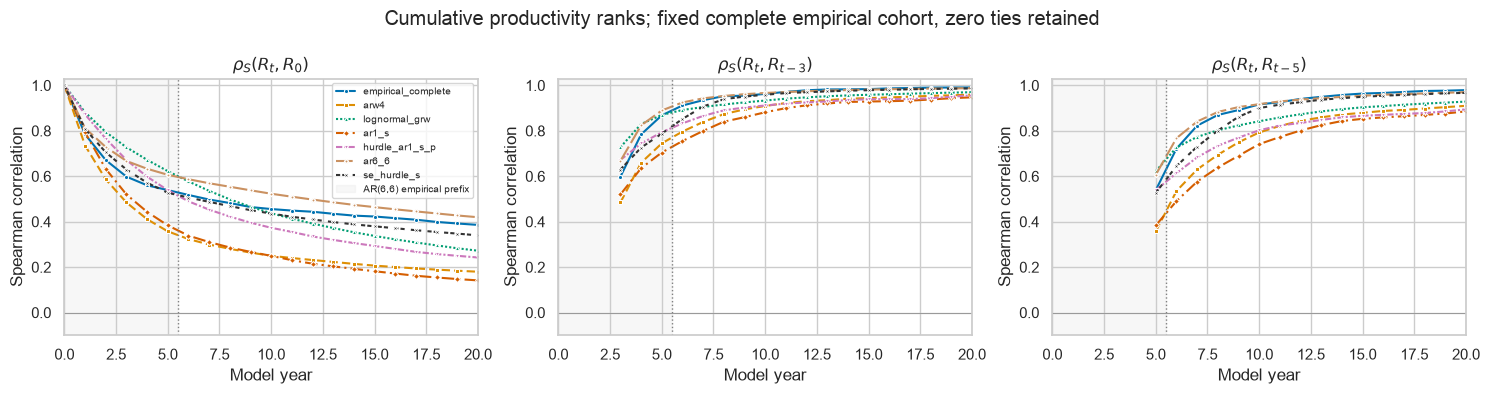

In [6]:
for DEST, selected in VIEWS:
    ORDER = ['empirical_complete'] + selected
    for measure in ['annual','cumulative']:
        fig,axes = plt.subplots(1,3,figsize=(15,4))
        titles = [r'$\rho_S(R_t,R_0)$',r'$\rho_S(R_t,R_{t-3})$',r'$\rho_S(R_t,R_{t-5})$']
        for ax,reference,title in zip(axes,['age_0','lag_3','lag_5'],titles):
            subset = ranks.loc[ranks.measure.eq(measure) & ranks.reference.eq(reference)]
            lines(subset,'age','rho',ax)
            if 'ar6_6' in selected: ax.axvspan(0,5.5,color='.8',alpha=.15,label='AR(6,6) empirical prefix')
            if 'ar6_6' in selected: ax.axvline(5.5,color='.5',linestyle=':',linewidth=1)
            ax.axhline(0,color='.6',lw=.7)
            ax.set(title=title,ylabel='Spearman correlation',xlabel='Model year',ylim=(-.1,1.03),xlim=(0,Y))
            if ax!=axes[0]:ax.legend().remove()
        axes[0].legend(fontsize=7)
        fig.suptitle(f'{measure.title()} productivity ranks; fixed complete empirical cohort, zero ties retained')
        save(fig,f'{measure}_rank_persistence')

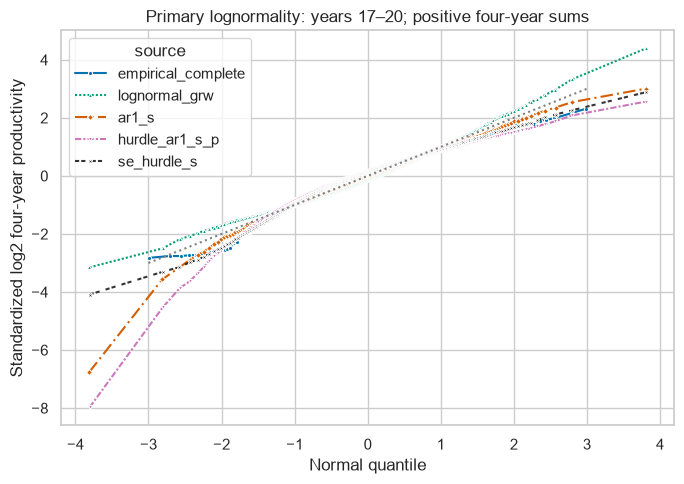

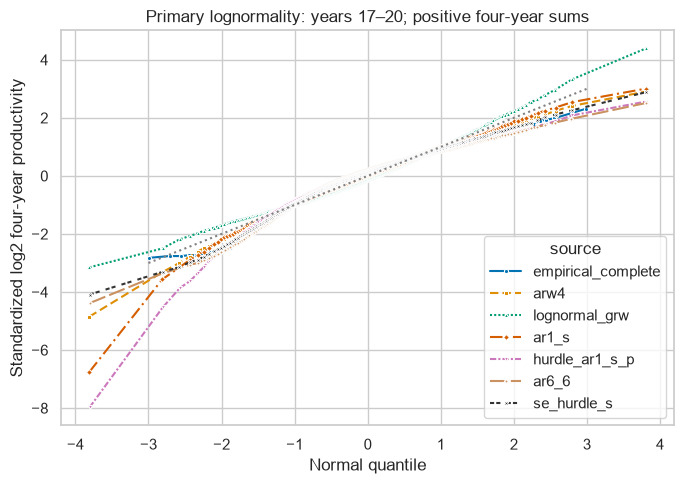

In [7]:
for DEST, selected in VIEWS:
    ORDER = ['empirical_complete'] + selected
    fig,ax = plt.subplots(figsize=(7,5))
    lines(qq.loc[qq.window.eq('last_four')],'normal_quantile','observed_quantile',ax)
    ax.plot([-3,3],[-3,3],color='.5',linestyle=':',label='Normal reference')
    ax.set(xlabel='Normal quantile',ylabel='Standardized log2 four-year productivity',title=f'Primary lognormality: years {Y-3}–{Y}; positive four-year sums')
    save(fig,'last_four_qq')

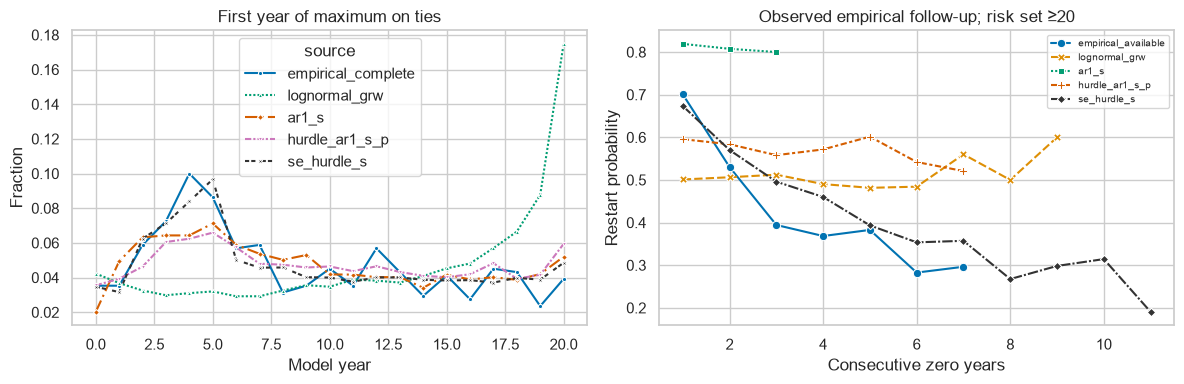

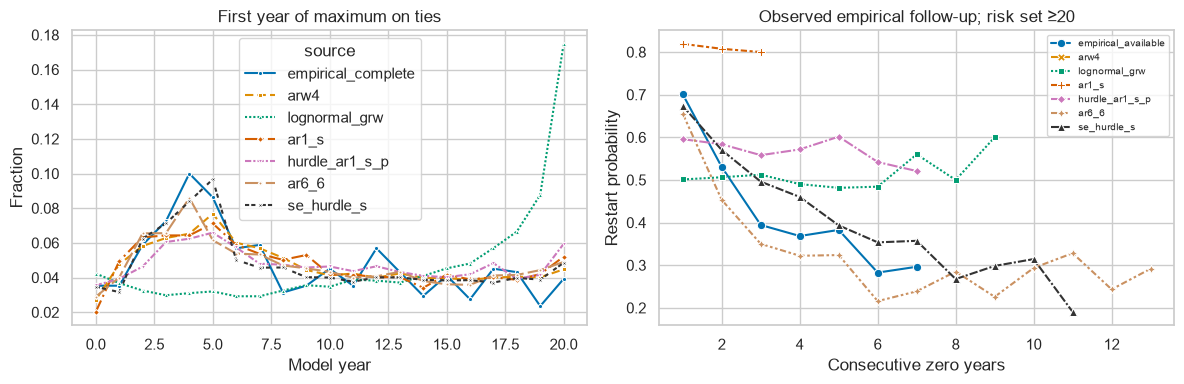

In [8]:
for DEST, selected in VIEWS:
    ORDER = ['empirical_complete'] + selected
    fig,axes = plt.subplots(1,2,figsize=(12,4))
    lines(maximum,'age','fraction',axes[0])
    axes[0].set(xlabel='Model year',ylabel='Fraction',title='First year of maximum on ties')
    # available follow-up for empirical hazard; generated transitions for simulations
    hazard_order = ['empirical_available'] + selected
    hazard_palette = dict(zip(hazard_order,sns.color_palette('colorblind',len(hazard_order))))
    hazard_palette['se_hurdle_s'] = PALETTE['se_hurdle_s']
    sns.lineplot(data=hazard.loc[hazard.n_at_risk.ge(20)],x='duration',y='restart_probability',
                 hue='source',style='source',hue_order=hazard_order,style_order=hazard_order,
                 palette=hazard_palette,markers=True,dashes=True,ax=axes[1])
    axes[1].set(xlabel='Consecutive zero years',ylabel='Restart probability',title='Observed empirical follow-up; risk set ≥20')
    axes[1].legend(fontsize=7)
    save(fig,'maximum_and_restart')

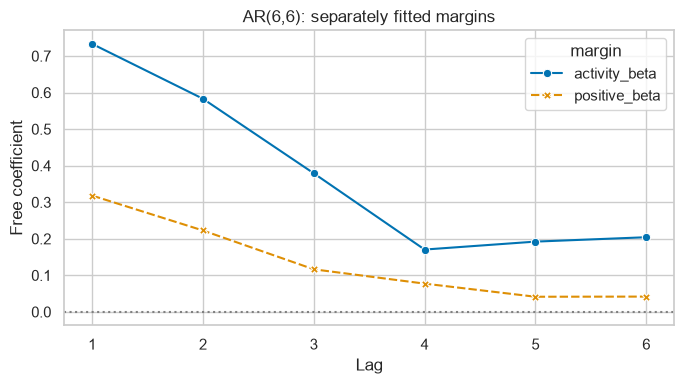

In [9]:
DEST = SECONDARY
profiles = params.melt(id_vars='lag',value_vars=['activity_beta','positive_beta'],var_name='margin',value_name='coefficient')
fig,ax = plt.subplots(figsize=(7,4))
sns.lineplot(data=profiles,x='lag',y='coefficient',hue='margin',style='margin',markers=True,dashes=True,palette='colorblind',ax=ax)
ax.axhline(0,color='.5',linestyle=':')
ax.set(xlabel='Lag',ylabel='Free coefficient',title='AR(6,6): separately fitted margins')
save(fig,'ar6_6_coefficients')